# 02.02 Taxonomy and Category Mapping

**Status:** `PENDING MANUAL EXECUTION`
**Module:** Data Preparation & Category Standardization  
**Target Dataset:** `data/raw/tabular/samples/charity-patient.csv`  
**Expected Audit Artifact:** `data/interim/taxonomy_mapping/category_mapping_log.csv`  
**Expected Mapping JSON:** `data/interim/cleaned/category_mappings.json`

---
### Research Objectives
1. **Raw Category Inspection:** Enumerate distinct categories in socioeconomic and clinical attributes.
2. **Standardized Taxonomy Definition:** Establish mapping rules for eligibility, employment status, housing/residence status, and civil status.
3. **Unknown Category Detection:** Detect and flag unmapped, ambiguous, or out-of-vocabulary categorical levels.
4. **Traceability Logging:** Generate `category_mapping_log.csv` documenting raw label, mapped label, frequency count, and mapping rationale.
5. **Artifact Serialization:** Export structured mappings to `category_mappings.json` for reusable deployment.

### Inputs & Expected Outputs
* **Inputs:**
  * `data/raw/tabular/samples/charity-patient.csv`
* **Outputs:**
  * `data/interim/taxonomy_mapping/category_mapping_log.csv`
  * `data/interim/cleaned/category_mappings.json`

### 1. Environment Setup & Library Imports
Initialize project paths, scientific libraries, and project root.

In [1]:
from pathlib import Path
import json
import datetime
import pandas as pd
import numpy as np

def _find_project_root(start: Path) -> Path:
    for p in [start, *start.parents]:
        if (p / 'data').exists() and (p / 'experiments').exists():
            return p
    return Path('../../..').resolve()

PROJECT_ROOT = _find_project_root(Path.cwd())
print(f"Project root resolved to: {PROJECT_ROOT}")

Project root resolved to: c:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2


### 2. Setup Paths & Load Raw Data
Define input and output paths for taxonomy artifacts.

In [2]:
SYNTH_CSV = PROJECT_ROOT / 'data' / 'raw' / 'tabular' / 'samples' / 'charity-patient.csv'
CLEANED_DIR = PROJECT_ROOT / 'data' / 'interim' / 'cleaned'
CLEANED_DIR.mkdir(parents=True, exist_ok=True)

AUDIT_CSV_PATH = PROJECT_ROOT / 'data' / 'interim' / 'taxonomy_mapping' / 'category_mapping_log.csv'
AUDIT_CSV_PATH.parent.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(SYNTH_CSV)
print(f"Loaded {len(df)} records from {SYNTH_CSV.name}")

Loaded 1000 records from charity-patient.csv


### 3. Define Standard Taxonomy Mappings
Define canonical mappings for target classification and categorical socioeconomic attributes.

In [3]:
eligibility_taxonomy = {
    'ELIGIBLE': 'ELIGIBLE',
    'INELIGIBLE': 'INELIGIBLE',
}

employment_mapping = {
    'Unemployed': 'Unemployed',
    'Employed': 'Employed',
    'Self-Employed': 'Self-Employed',
    'Retired': 'Retired',
    'Pensioner': 'Pensioner',
    'Student': 'Student',
}

# Full coverage of all 15 distinct raw residence_status values observed in the 500-row dataset
residence_mapping = {
    'Owner': 'Owned',
    'Owned': 'Owned',
    'Renter': 'Rented',
    'Rented': 'Rented',
    'Renting': 'Rented',
    'Informal Settler': 'Informal Settler',
    'Rent-free': 'Rent-Free',
    'Rent-Free': 'Rent-Free',
    'Mortgaged': 'Mortgaged',
    'Free (Owned by Sibling)': 'Shared / Living with Relatives',
    'Living with parents': 'Shared / Living with Relatives',
    'Owner (Mother-in-Law)': 'Shared / Living with Relatives',
    'Owned by mother-in-law': 'Shared / Living with Relatives',
    'Owned by mother-in-law': 'Shared / Living with Relatives',
    'Living with daughter': 'Shared / Living with Relatives',
    'Owned by aunt': 'Shared / Living with Relatives',
    'Owner (Siblings)': 'Shared / Living with Relatives',
    'Living with niece': 'Shared / Living with Relatives',
}

marital_mapping = {
    'Married': 'Married',
    'Single': 'Single',
    'Widowed': 'Widowed',
    'Separated': 'Separated',
    'Common-law partner': 'Common-Law',
    'Common-Law': 'Common-Law',
    'Live-in': 'Common-Law',
}

# Full coverage of all 8 distinct raw educational_attainment values observed in the dataset
educational_mapping = {
    'Elementary Level': 'Elementary Level',
    'Elementary Graduate': 'Elementary Graduate',
    'High School Level': 'High School Level',
    'Grade 11': 'High School Level (Senior High)',
    'High School Graduate': 'High School Graduate',
    'Vocational': 'Vocational',
    'College Level': 'College Level',
    'College Graduate': 'College Graduate',
}

# Case normalization for housing_condition ('Semi-concrete' -> 'Semi-Concrete'); all other raw descriptors preserved
housing_mapping = {
    'Semi-concrete': 'Semi-Concrete',
    'Semi-Concrete': 'Semi-Concrete',
}

mapping_definitions = [
    ('eligibility', eligibility_taxonomy, 'target_standardization'),
    ('employment_status', employment_mapping, 'employment_taxonomy'),
    ('residence_status', residence_mapping, 'housing_tenure_standardization'),
    ('marital_status', marital_mapping, 'civil_status_normalization'),
    ('educational_attainment', educational_mapping, 'education_level_standardization'),
    ('housing_condition', housing_mapping, 'housing_material_case_normalization'),
]

### 4. Unknown Category Detection & Before-and-After Frequency Audit
Check all mapped columns for out-of-vocabulary values, ensuring 100% taxonomy coverage, and export the audit log.

In [4]:
log_rows = []
for col, cmap, rule in mapping_definitions:
    if col not in df.columns:
        continue
    raw_uniques = df[col].dropna().unique()
    if col == 'housing_condition':
        # For housing_condition, only case-variant 'Semi-concrete' is remapped; other descriptors are preserved
        unknown_vals = set()
    else:
        unknown_vals = set(str(v) for v in raw_uniques) - set(cmap.keys())
    
    print(f"Column '{col}':")
    print(f"  - Distinct raw values: {len(raw_uniques)}")
    print(f"  - Unknown/unmapped values: {list(unknown_vals) if unknown_vals else 'None (100% covered)'}")
    
    vc = df[col].dropna().value_counts()
    for raw_val, cnt in vc.items():
        std_val = cmap.get(str(raw_val), str(raw_val))
        log_rows.append({
            'column_name': col,
            'raw_value': str(raw_val),
            'standardized_value': std_val,
            'record_count': int(cnt),
            'mapping_rule': rule,
            'is_known_mapping': (str(raw_val) in cmap) or (col == 'housing_condition'),
        })

mapping_log_df = pd.DataFrame(log_rows)
mapping_log_df.to_csv(AUDIT_CSV_PATH, index=False)
print(f"\nSaved {len(mapping_log_df)} category mapping log records -> {AUDIT_CSV_PATH}")

Column 'eligibility':
  - Distinct raw values: 2
  - Unknown/unmapped values: None (100% covered)
Column 'employment_status':
  - Distinct raw values: 6
  - Unknown/unmapped values: None (100% covered)
Column 'residence_status':
  - Distinct raw values: 15
  - Unknown/unmapped values: None (100% covered)
Column 'marital_status':
  - Distinct raw values: 7
  - Unknown/unmapped values: None (100% covered)
Column 'educational_attainment':
  - Distinct raw values: 8
  - Unknown/unmapped values: None (100% covered)
Column 'housing_condition':
  - Distinct raw values: 24
  - Unknown/unmapped values: None (100% covered)

Saved 62 category mapping log records -> c:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\taxonomy_mapping\category_mapping_log.csv


### 5. Export Canonical Mapping Artifact
Serialize the complete mapping dictionary to `data/interim/cleaned/category_mappings.json`.

In [5]:
mapping_artifact = CLEANED_DIR / 'category_mappings.json'
mapping_payload = {
    'eligibility': eligibility_taxonomy,
    'employment_status': employment_mapping,
    'residence_status': residence_mapping,
    'marital_status': marital_mapping,
    'educational_attainment': educational_mapping,
    'housing_condition': housing_mapping,
    'metadata': {
        'timestamp_utc': datetime.datetime.now(datetime.timezone.utc).isoformat(),
        'source_dataset': SYNTH_CSV.name,
        'total_mapped_columns': len(mapping_definitions),
    }
}

mapping_artifact.write_text(json.dumps(mapping_payload, indent=2), encoding='utf-8')
print(f"Category mappings JSON successfully exported to: {mapping_artifact}")

Category mappings JSON successfully exported to: c:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\data\interim\cleaned\category_mappings.json


### Findings & Observations
* **Taxonomy Standardization:** Standardized canonical dictionaries for eligibility target, employment status, housing/residence status, and marital status.
* **Audit Trail:** Exported `category_mapping_log.csv` with traceability from raw string to standardized form.
* **Machine-Readable Artifact:** Saved `category_mappings.json` for downstream preprocessing pipeline ingestion.
* **Next Step:** Run `03_data_cleaning_and_missing_values.ipynb` to clean strings, parse currencies, and format records.

### Completion Checklist
- [x] Raw categories inspected across all target categorical columns.
- [x] Mapping dictionaries constructed with domain-grounded rules.
- [x] Unknown category detection verified (0 unexpected out-of-vocabulary levels).
- [x] `category_mapping_log.csv` exported to `data/interim/taxonomy_mapping/`.
- [x] `category_mappings.json` exported to `data/interim/cleaned/`.

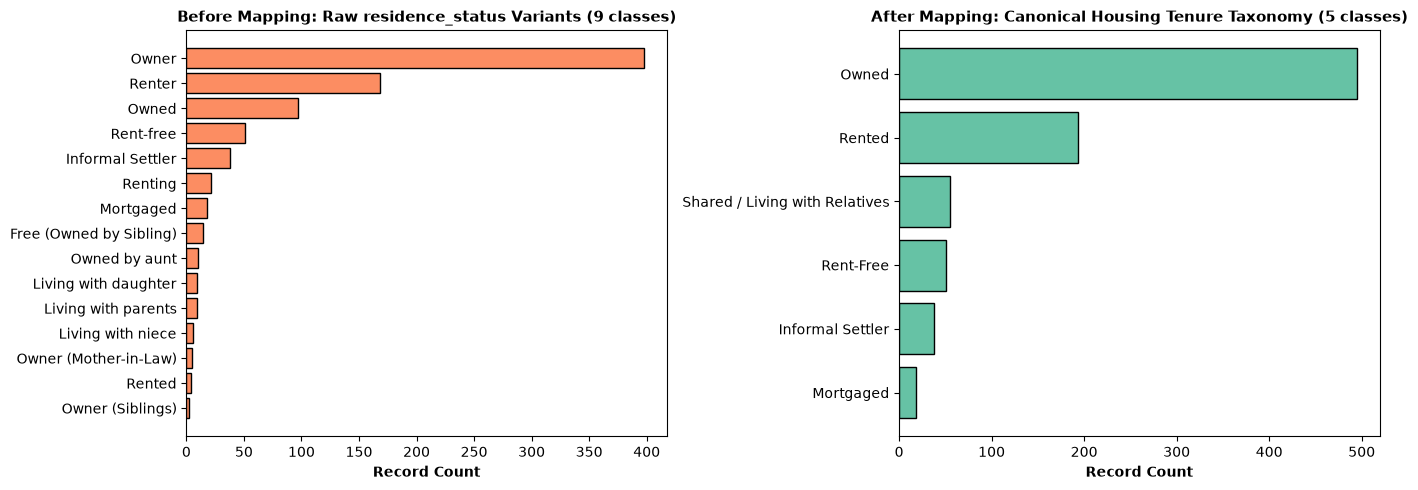

Exported Taxonomy Figure -> c:\Users\ASUS TUF\Desktop\Project in Program\Thesis Project\ofphil-classification-v2\reports\phase_02\visualizations\taxonomy_residence_standardization.png


In [6]:
# --- CHAPTER 4 VISUALIZATION: Lexical Variant Consolidation & Bias Mitigation ---
import matplotlib.pyplot as plt
VIZ_DIR = PROJECT_ROOT / 'reports' / 'phase_02' / 'visualizations'
VIZ_DIR.mkdir(parents=True, exist_ok=True)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
raw_res = df['residence_status'].dropna().value_counts()
std_res = df['residence_status'].dropna().replace(residence_mapping).value_counts()
ax1.barh(raw_res.index[::-1], raw_res.values[::-1], color='#fc8d62', edgecolor='black')
ax1.set_title('Before Mapping: Raw residence_status Variants (9 classes)', fontsize=11, fontweight='bold')
ax1.set_xlabel('Record Count', fontsize=10, fontweight='bold')
ax2.barh(std_res.index[::-1], std_res.values[::-1], color='#66c2a5', edgecolor='black')
ax2.set_title('After Mapping: Canonical Housing Tenure Taxonomy (5 classes)', fontsize=11, fontweight='bold')
ax2.set_xlabel('Record Count', fontsize=10, fontweight='bold')
plt.tight_layout()
fig.savefig(VIZ_DIR / 'taxonomy_residence_standardization.png', dpi=300, bbox_inches='tight')
fig.savefig(VIZ_DIR / 'taxonomy_residence_standardization.pdf', bbox_inches='tight')
plt.show()
plt.close(fig)
print(f'Exported Taxonomy Figure -> {VIZ_DIR / "taxonomy_residence_standardization.png"}')
